# How well is EI optimized? A deterministic, gradient-refined EI as the base policy

## Description

<!-- Written 2026-11-12 before the first run (pre-registration). Issue #13; research_log/decisions/0007; Tim's question on candidate selection. -->

**Question.**
- π₀ (EI) so far is the argmax of the PFN's EI over a fresh random candidate set at every (task, step, replicate). The set is 1024 shifted Sobol points plus 64 Gaussian perturbations of the incumbent at each of σ ∈ {0.01, 0.05, 0.2}, with no refinement.
- That makes π₀ stochastic. On noise-free tasks, this is the *only* noise in the round-1 labels: the continuations differ only in EI's candidate sets.
- It also confounds the advantage over EI with EI's own optimizer error. A candidate with higher EI than the sampled argmax "beats EI", although EI properly optimized would have chosen it.
- A scratch check (600 labeled states, not tracked) gave the motivation:
  - the sampled argmax reaches about 99.5% of the best EI found (median), so the value lost is small;
  - but picks from two replicate candidate sets differ by a median distance of 0.005–0.018. That is large where the incumbent is within one PFN bin of f\* (57% of the labeled states; 0007 §3).
- This experiment asks:
  1. how suboptimal and how stochastic the current EI is;
  2. whether a deterministic, gradient-refined EI loses anything in BO;
  3. whether it can be π₀ for relabeling. With deterministic π₀ on noise-free tasks, a label needs a single continuation and no cross-fitting.

**Setup** (`experimental/ei_opt.py`, `tasks/ei_opt.py`). Four variants of EI, the same PFN (pfn_large, fp32), the same EI closed form:
- `sampled`: the current π₀.
- `fixed`: candidate sets of the same sizes, but a function of the data only. The Sobol set is unshifted, and the perturbation directions around the incumbent are fixed: one draw shared by all lanes and steps.
- `sampled+refine`, `fixed+refine`:
  - the top 8 candidates by EI are the starts;
  - Adam on x through the PFN (it is differentiable in x) maximizes log EI: 100 steps, lr 0.01 cosine-annealed to 1e-4, clamped to [0, 1];
  - the best iterate per start is kept (iterates at an evaluated point are excluded);
  - the pick is the best of the refined starts and the base argmax, so refinement never lowers EI.
- *Part A (states).*
  - On the first 2000 labeled states of the pinned round-1 label set (split 4, d = 2), every variant picks under 4 replicate candidate sets.
  - Per pick: its EI relative to the best EI any variant found at the state, and the true f at the pick in PFN bins relative to the incumbent.
  - Per state and variant: the mean pairwise distance between replicate picks, and the sd of f at the picks.
- *Part B (rollouts).*
  - Full BO runs (n_init = 4, T = 20) of every variant on 1000 tasks of **split 0**: the tuning split, because this chooses π₀.
  - 4 replicates each: the replicate selects the candidate-set nuisance, which the fixed variants ignore.
  - Final regret per (task, variant, replicate): normalized regret (% of f_med − f\*), regret in PFN bins (ECDF units / 0.001), and log regret.
  - f\* is lowered by every run.

**What to look for.**
1. Part B, the decision: the paired difference (replicate mean per task) of `fixed+refine` − `sampled` in normalized regret, relative, with a bootstrap CI over tasks. Also its determinism: the share of tasks with replicate sd of the final regret < 1e-6 bins.
2. Part B, the size of the label noise π₀ induces: the replicate sd of the final normalized regret per task for each variant. `sampled` is the noise the round-1 labels carried.
3. Part B, the tail: the q90 and q95 of the per-task normalized regret, and the failure rate P(final regret > 10 bins), by variant.
4. Part A:
   - the EI ratio (median, q10, share < 0.99) and the replicate pick distance by variant;
   - by step t and by incumbent gap in bins: where does the sampled argmax lose most?

**GO / NO-GO** (rule `analysis/ei_opt.py::ei_opt_verdict`, worthwhile = 5% relative). This decides whether `fixed+refine` becomes π₀ for the next labels.
- **GO**: `fixed+refine` is deterministic (≥ 99% of tasks with replicate sd < 1e-6 bins) and not worse than `sampled` by 5% (the upper CI bound of the relative paired difference < +5%).
- **NO-GO**: not deterministic, or clearly worse (lower bound > +5%).
- **INCONCLUSIVE**: otherwise.

A *better* `fixed+refine` would be a bonus, not required. The point is removing the optimizer noise without losing performance.

**Limits.**
- Noise-free P0, d = 2, T = 20 only (pfn_large valid for n ≤ 100; contexts n ≤ 24).
- Refinement can still miss a better basin of EI that none of the top-8 starts lies in. Part A's EI ratio is relative to the best *found*, not the true maximum.
- GPU non-determinism could make "deterministic" variants differ across replicates; the determinism check measures exactly that.
- 1000 tasks is a pilot size for small effects.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from anytime_acq.analysis import load_snapshot, show_header
from anytime_acq.analysis.ei_opt import ei_opt_verdict, pick_dispersion
from anytime_acq.tasks.pfn_bo_inference import gap_stratum

SNAPSHOT = "results/ei_opt/pilot_20261112-091043"
snap = load_snapshot(SNAPSHOT)
show_header(snap)  # how it was run + configuration, generated from the snapshot

## How it was run

```bash
just sweep detached pilot experiment=ei_opt task.d=2
```

|  |  |
|---|---|
| stage | pilot |
| sweep | `pilot_20261112-091043` |
| commit | `295a9b90b750` (tag `sweep/ei_opt/pilot_20261112-091043`) |
| backend / host | detached / ulysses |
| ran | 2026-11-12T09:10:45 → 2026-11-12T09:37:06 |
| members | 1: 1 done |
| compute | 26.3 min wall, 0.0 min GPU |

## Configuration

Experiment config (`configs/experiment/ei_opt.yaml`):

```yaml
# @package _global_
# How well is EI optimized, and a deterministic gradient-refined EI as the base policy (issue #13, decision 0007).
# Pre-registration: notebooks/11_2026-11-12_ei_opt.ipynb.
defaults:
  - override /task: ei_opt

task:
  d: 2
```

**Varying:** nothing

**Replicates:** none

**Constant:**

```yaml
seed: 0
task:
  T_per_d: 10
  candidates.local_sigmas: '[0.01, 0.05, 0.2]'
  candidates.n_local: 64
  candidates.n_sobol: 1024
  chunk: 256
  d: 2
  device: cuda
  group: 256
  labels.path: api_round1/pilot_20261111-133311/0/tracking/artifacts/labels.pt
  labels.sha256: c27d893923d0f003ed7b1e1148ad6670c1f5fb061ac7cdf137eb2a8a64c678d9
  log_eps: 1.0e-06
  n_init_per_d: 2
  n_reps: 4
  name: ei_opt
  pfn: pfn_large
  refine.k: 8
  refine.lr: 0.01
  refine.steps: 100
  rollouts.n_tasks: 1000
  rollouts.split: 0
  rollouts.task_draw.n_dense: 16384
  rollouts.task_draw.n_refine: 16
  rollouts.task_draw.refine_steps: 200
  rollouts.task_offset: 0
  states.n_states: 2000
  states.task_draw.n_dense: 256
  states.task_draw.n_refine: 1
  states.task_draw.refine_steps: 1
  tf32: false
```

In [ ]:
runs = snap.runs
print("member status:", runs.status.value_counts().to_dict())
S = runs.iloc[0]
print("minutes:", {k: round(float(S[k]) / 60, 1) for k in runs.columns if k.startswith("time/")})
st, fin, spread, summary, paired = (snap.table(k) for k in ("states", "final", "spread", "summary", "paired"))
print("states:", st.state.nunique(), "| rollout tasks:", fin.task.nunique(), "| replicates:", fin.rep.nunique(),
      "| variants:", sorted(fin.variant.unique()))

member status: {'DONE': 1}
minutes: {'time/rollouts_s': 22.8, 'time/states_s': 3.4}
states: 2000 | rollout tasks: 1000 | replicates: 4 | variants: ['fixed', 'fixed+refine', 'sampled', 'sampled+refine']


## 1. Part A: how suboptimal and how stochastic is the EI pick at the labeled states?

EI ratio = EI of the pick / best EI any variant found at the state. Pick distance = mean pairwise distance between the 4 replicate picks. f sd = sd over replicates of the true f at the pick, in PFN bins.

In [ ]:
cols = ["variant", "ei_ratio_median", "ei_ratio_q10", "share_ei_ratio_below_0.99", "pick_dist_mean",
        "share_states_pick_dist_above_1e-3", "f_sd_bins_median", "f_sd_bins_mean"]
display(summary[cols].set_index("variant").round(4))
disp = pick_dispersion(st)
disp["stratum"] = gap_stratum(disp.gap_bins.to_numpy())
disp["t_bin"] = pd.cut(disp.t, [-1, 4, 9, 14, 20])
print("pick distance (mean) by incumbent gap stratum:")
display(disp.pivot_table(index="stratum", columns="variant", values="pick_dist", aggfunc="mean").round(4))
print("f sd over replicates (bins, mean) by gap stratum:")
display(disp.pivot_table(index="stratum", columns="variant", values="f_sd_bins", aggfunc="mean").round(3))
print("EI ratio (mean) by step:")
display(disp.pivot_table(index="t_bin", columns="variant", values="ei_ratio", aggfunc="mean", observed=True).round(4))

,ei_ratio_median,ei_ratio_q10,share_ei_ratio_below_0.99,pick_dist_mean,share_states_pick_dist_above_1e-3,f_sd_bins_median,f_sd_bins_mean
variant,,,,,,,
fixed,0.9948,0.9452,0.3765,0.0000,0.00,0.0000,0.0000
fixed+refine,1.0000,1.0000,0.0540,0.0000,0.00,0.0000,0.0000
sampled,0.9947,0.9438,0.3911,0.0567,0.90,0.1017,7.2060
sampled+refine,1.0000,1.0000,0.0531,0.0288,0.11,0.0008,1.4858


pick distance (mean) by incumbent gap stratum:


variant,fixed,fixed+refine,sampled,sampled+refine
stratum,,,,
1-10,0.0,0.0,0.0324,0.0071
10-100,0.0,0.0,0.0361,0.0072
<1,0.0,0.0,0.0713,0.0441
>100,0.0,0.0,0.0508,0.0129


f sd over replicates (bins, mean) by gap stratum:


variant,fixed,fixed+refine,sampled,sampled+refine
stratum,,,,
1-10,0.0,0.0,7.002,0.637
10-100,0.0,0.0,12.026,1.647
<1,0.0,0.0,4.335,1.750
>100,0.0,0.0,19.170,0.925


EI ratio (mean) by step:


variant,fixed,fixed+refine,sampled,sampled+refine
t_bin,,,,
"(-1, 4]",0.9874,0.9984,0.9870,0.9987
"(4, 9]",0.9765,0.9931,0.9757,0.9946
"(9, 14]",0.9760,0.9928,0.9746,0.9926
"(14, 20]",0.9751,0.9947,0.9765,0.9941


## 2. Part B: full BO runs on split 0 (paired over tasks, replicate means)

,norm_regret_mean,norm_regret_q90,norm_regret_q95,regret_bins_mean,fail_rate,rep_sd_norm_median,rep_sd_norm_mean,share_tasks_deterministic
variant,,,,,,,,
fixed,1.6566,2.2057,7.9356,4.7593,0.0790,0.0000,0.0000,1.000
fixed+refine,1.5484,2.3921,8.6959,4.4126,0.0800,0.0000,0.0000,1.000
sampled,1.6412,3.6143,8.6701,4.8099,0.0828,0.0072,0.7853,0.190
sampled+refine,1.5915,2.4621,8.5236,4.5996,0.0810,0.0003,0.1154,0.217


,a,b,metric,n,delta,lo,hi,rel,rel_lo,rel_hi,frac_a_better,frac_tied
0,sampled+refine,sampled,norm_regret,1000,-0.0497,-0.2491,0.1373,-0.0303,-0.1518,0.0837,0.441,0.190
1,sampled+refine,sampled,regret_bins,1000,-0.2103,-0.9472,0.5082,-0.0437,-0.1969,0.1057,0.441,0.190
2,sampled+refine,sampled,log_regret,1000,0.0579,0.0183,0.0983,-0.0129,-0.0041,-0.0219,0.376,0.190
3,fixed,sampled,norm_regret,1000,0.0154,-0.1744,0.2158,0.0094,-0.1063,0.1315,0.496,0.188
4,fixed,sampled,regret_bins,1000,-0.0505,-0.7914,0.7045,-0.0105,-0.1645,0.1465,0.496,0.188
5,fixed,sampled,log_regret,1000,-0.0293,-0.0744,0.0149,0.0065,0.0166,-0.0033,0.422,0.186
6,fixed+refine,sampled,norm_regret,1000,-0.0928,-0.3186,0.1150,-0.0565,-0.1941,0.0701,0.448,0.189
7,fixed+refine,sampled,regret_bins,1000,-0.3973,-1.2343,0.3561,-0.0826,-0.2566,0.0740,0.448,0.189
8,fixed+refine,sampled,log_regret,1000,0.0556,0.0129,0.0996,-0.0124,-0.0029,-0.0222,0.366,0.189


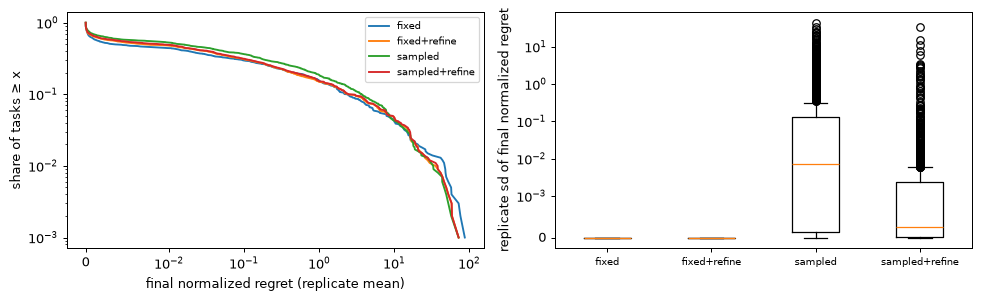

In [ ]:
cols = ["variant", "norm_regret_mean", "norm_regret_q90", "norm_regret_q95", "regret_bins_mean", "fail_rate",
        "rep_sd_norm_median", "rep_sd_norm_mean", "share_tasks_deterministic"]
display(summary[cols].set_index("variant").round(4))
show = ["a", "b", "metric", "n", "delta", "lo", "hi", "rel", "rel_lo", "rel_hi", "frac_a_better", "frac_tied"]
display(paired[show].round(4))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4), dpi=90)
m = fin.groupby(["task", "variant"]).norm_regret.mean().unstack()
for v in m.columns:
    x = np.sort(m[v].to_numpy()); ax[0].plot(x, 1 - np.arange(len(x)) / len(x), label=v)
ax[0].set_xscale("symlog", linthresh=0.01); ax[0].set_yscale("log"); ax[0].set_xlabel("final normalized regret (replicate mean)")
ax[0].set_ylabel("share of tasks ≥ x"); ax[0].legend(fontsize=8)
sp = spread.pivot_table(index="task", columns="variant", values="sd_norm")
ax[1].boxplot([sp[v].to_numpy() for v in sp.columns], tick_labels=list(sp.columns)); ax[1].set_yscale("symlog", linthresh=1e-3)
ax[1].set_ylabel("replicate sd of final normalized regret"); ax[1].tick_params(axis="x", labelsize=8)
plt.tight_layout(); plt.show()

## Observations (pilot, snapshot `results/ei_opt/pilot_20261112-091043`)

Written after the run.
- **The current EI is stochastic, but loses little EI value.**
  - Sampled replicate picks differ by more than 1e-3 in 90% of states (mean distance 0.057).
  - Their EI ratio is still 0.995 (median), with q10 0.944.
  - The true f at the pick varies across replicates by a mean sd of 7.2 bins, mostly at states still far from f\* (19 bins for > 100 bins).
  - The resulting replicate sd of the final normalized regret is median 0.0072, mean 0.79. This is the noise the round-1 labels carried.
- **Refinement makes the pick (nearly) deterministic.**
  - From random starts (`sampled+refine`), 11% of states still differ by more than 1e-3, mostly within one bin of f\* (0.044): EI has several near-equal maxima there.
  - `fixed` and `fixed+refine` are exactly deterministic on 100% of tasks.
- **The decision (normalized regret).**
  - `fixed+refine` − `sampled` = −5.7% [−19%, +7%] over 1000 split-0 tasks.
  - It is not clearly worse, and possibly better, but the CI does not exclude +5%. The pre-registered verdict is **INCONCLUSIVE**.
- **On log regret, refinement is significantly worse.** These are paired Δ in log10 units, positive = worse:
  - `fixed+refine` +0.056 [0.013, 0.100];
  - `sampled+refine` +0.058 [0.018, 0.098];
  - `fixed` (unrefined) −0.029 [−0.074, 0.015].
  - About +0.056 log10 means a roughly 14% larger regret in geometric mean. Precisely maximizing the PFN's EI costs late-stage precision. A plausible but untested cause: EI's exact maximum sits near the incumbent at a scale where the PFN models noise (about one bin), so the refined picks are less useful there than the scattered local perturbations.
  - Log regret is secondary in this pre-registration. It is reported here because the reward of interest has since been clarified as rewarding progress near the optimum (Tim, 2026-11-12).
- **Tail** (q95 of per-task normalized regret) and failure rate (> 10 bins): about equal across variants (q95 7.9–8.7, failure rate 0.079–0.083).
- **Post hoc, not covered by the rule.** Unrefined `fixed` is deterministic and indistinguishable from `sampled` on both scales (norm +0.9% [−11%, +13%]; log −0.029 [−0.074, 0.015]). It is the natural deterministic π₀, but it needs its own pre-registered check on the reward we will use.


## Verdict

In [ ]:
print("verdict (analysis/ei_opt.py::ei_opt_verdict):", ei_opt_verdict(summary, paired))

verdict (analysis/ei_opt.py::ei_opt_verdict): INCONCLUSIVE
